In [1]:
# Running outside Kaggle: use the token saved by `hf auth login` (or the HF_TOKEN env var).
from huggingface_hub import whoami

try:
    print('Hugging Face login: OK as', whoami()['name'])
except Exception as exc:
    print('HF login not found. Run `hf auth login` in a terminal first:', exc)


Hugging Face login: OK as CYH4157


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

In [3]:
# TODO for Question 4
# Full SVD of the query projection (q_proj) weights of layers 0, 7, 15,
# then the minimum target rank that retains at least 50% cumulative energy.
from pathlib import Path

import numpy as np
import pandas as pd

LAYERS = [0, 7, 15]
ENERGY_THRESHOLD = 50.0   # %
TOP_K = 200               # only the first 200 singular values are visualized

Q4_DIR = Path.home() / 'BigData2026-Assignment1' / 'outputs' / 'q4'
Q4_DIR.mkdir(parents=True, exist_ok=True)

svd_results = {}
rows = []
for k in LAYERS:
    # Analyze the weights of the query projection layer (q_proj) where layer = k
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

    # Full SVD (no target rank): U (left singular vectors), S (singular values), Vh (right singular vectors)
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    # Retained energy ratio (cumulative energy) of the top-r singular values, r = 1..len(S)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # Smallest r whose cumulative energy >= 50%
    min_rank = int(torch.nonzero(energy_ratios >= ENERGY_THRESHOLD)[0].item()) + 1

    svd_results[k] = {'S': S.numpy(), 'energy': energy_ratios.numpy(), 'min_rank': min_rank}
    rows.append({
        'layer': k,
        'shape': tuple(q_weight.shape),
        'full_rank': len(S),
        'min_rank_for_50%_energy': min_rank,
        'energy_at_min_rank (%)': round(energy_ratios[min_rank - 1].item(), 2),
        'energy_of_top_200 (%)': round(energy_ratios[TOP_K - 1].item(), 2),
        'sigma_1': round(S[0].item(), 4),
        'sigma_200': round(S[TOP_K - 1].item(), 4),
        'sigma_min': round(S[-1].item(), 4),
    })

min_rank_df = pd.DataFrame(rows)
min_rank_df.to_csv(Q4_DIR / 'q4_min_rank.csv', index=False)
print(min_rank_df.to_string(index=False))


 layer        shape  full_rank  min_rank_for_50%_energy  energy_at_min_rank (%)  energy_of_top_200 (%)  sigma_1  sigma_200  sigma_min
     0 (2048, 2048)       2048                       62                   50.17                  71.24  31.3584     2.4260     0.0000
     7 (2048, 2048)       2048                      120                   50.20                  63.54  10.3367     1.9759     0.0001
    15 (2048, 2048)       2048                       84                   50.12                  68.84  12.8815     1.7040     0.0001


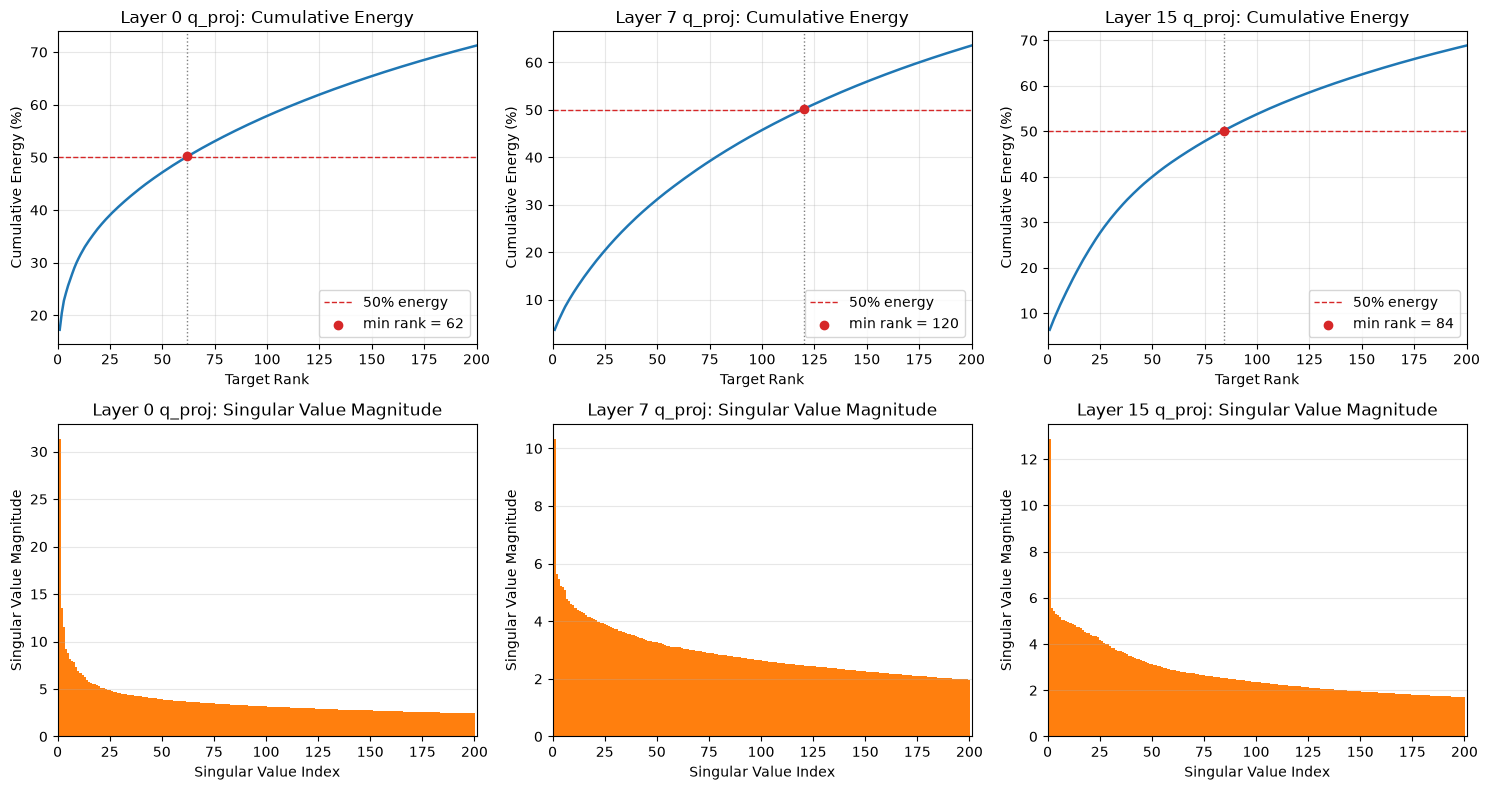

Figures saved to /home/nchc/BigData2026-Assignment1/outputs/q4


In [4]:
# Visualization for Layer 0, 7, 15 (first 200 singular values):
#   - Cumulative energy (%) -> line chart
#   - Singular value magnitude -> bar chart
plt.rcParams.update({'font.size': 10})
ranks = np.arange(1, TOP_K + 1)


def plot_energy(ax, k):
    res = svd_results[k]
    r = res['min_rank']
    ax.plot(ranks, res['energy'][:TOP_K], color='tab:blue', linewidth=1.8)
    ax.axhline(ENERGY_THRESHOLD, color='tab:red', linestyle='--', linewidth=1, label='50% energy')
    ax.axvline(r, color='tab:gray', linestyle=':', linewidth=1)
    ax.scatter([r], [res['energy'][r - 1]], color='tab:red', zorder=3,
               label=f'min rank = {r}')
    ax.set_title(f'Layer {k} q_proj: Cumulative Energy')
    ax.set_xlabel('Target Rank')
    ax.set_ylabel('Cumulative Energy (%)')
    ax.set_xlim(0, TOP_K)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')


def plot_magnitude(ax, k):
    res = svd_results[k]
    ax.bar(ranks, res['S'][:TOP_K], width=1.0, color='tab:orange')
    ax.set_title(f'Layer {k} q_proj: Singular Value Magnitude')
    ax.set_xlabel('Singular Value Index')
    ax.set_ylabel('Singular Value Magnitude')
    ax.set_xlim(0, TOP_K + 1)
    ax.grid(axis='y', alpha=0.3)


# One file per chart (6 charts in total)
for k in LAYERS:
    for kind, fn in [('energy', plot_energy), ('magnitude', plot_magnitude)]:
        fig, ax = plt.subplots(figsize=(5, 3.5))
        fn(ax, k)
        fig.tight_layout()
        fig.savefig(Q4_DIR / f'layer{k}_{kind}.png', dpi=200)
        plt.close(fig)

# All 6 charts in one figure (compact version for the report)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, k in enumerate(LAYERS):
    plot_energy(axes[0, j], k)
    plot_magnitude(axes[1, j], k)
fig.tight_layout()
fig.savefig(Q4_DIR / 'q4_all_layers.png', dpi=200)
plt.show()
print('Figures saved to', Q4_DIR)
